# Statistical Analysis of MetroPT-3 Compressor Sensor Behavior
**Peyman Mohammad Hassan**

**Dataset:** MetroPT-3 (UCI Machine Learning Repository). This statistical analysis examines real measurements from a railway air compressor using descriptive statistics, graphical comparisons and a hypothesis test of observed operating states. It supports the research-oriented condition-monitoring module of QIAIP ERP; it does not assert confirmed failures or causal links.

**Research question:** On recording days when both compressor operating-signal states occur, does mean panel pressure (TP3) differ between COMP=1 and COMP=0 observations?

**Source and data limits:** 30,339 real recorded rows, 17 columns, deterministically sampled (every 50th original row) from a larger 1,516,948-row UCI dataset. Observations are from one compressor; readings are temporally correlated; operating states are not randomized. The original observations are not individually labeled as faults.


## 1. Load CSV and inspect its schema
The CSV is alongside this notebook. No ERP login, QIAIP API, or generated simulation is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
sns.set_theme(style='whitegrid')
df = pd.read_csv('metropt3_compressor_sample.csv')
print('Dataset shape:',df.shape)
display(df.head())
print('Column types and missingness:')
display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().to_frame('missing'))
assert len(df)>=500 and df.shape[1]>=6


Dataset shape: (30339, 17)


,source_row_index,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,500,2020-02-01 00:08:15,-0.014,8.854,8.840,-0.022,8.856,52.725,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,1000,2020-02-01 00:16:31,-0.016,8.398,8.384,-0.022,8.398,51.100,0.0350,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,1500,2020-02-01 00:24:47,10.062,10.034,-0.012,-0.024,10.030,50.025,6.2825,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,2000,2020-02-01 00:33:02,-0.012,9.422,9.408,-0.024,9.426,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


Column types and missingness:


,dtype
source_row_index,int64
timestamp,str
TP2,float64
TP3,float64
H1,float64
DV_pressure,float64
Reservoirs,float64
Oil_temperature,float64
Motor_current,float64
COMP,float64


,missing
source_row_index,0
timestamp,0
TP2,0
TP3,0
H1,0
DV_pressure,0
Reservoirs,0
Oil_temperature,0
Motor_current,0
COMP,0


## 2. Documented cleaning and quality controls
The functions below parse source data faithfully and remove malformed essential records, without generating measurements or classifying faults.

In [2]:
def parse_measurements(frame: pd.DataFrame) -> pd.DataFrame:
    """Parse source timestamps and numeric sensor columns; retain invalid values as NaN for review."""
    result=frame.copy()
    result['timestamp']=pd.to_datetime(result['timestamp'],errors='coerce')
    for col in result.columns.difference(['timestamp']):
        result[col]=pd.to_numeric(result[col],errors='coerce')
    return result

def preserve_valid_observations(frame: pd.DataFrame) -> pd.DataFrame:
    """Remove malformed timestamp/essential sensor/state rows and duplicate source identifiers."""
    result=frame.replace([np.inf,-np.inf],np.nan)
    result=result.dropna(subset=['timestamp','source_row_index','TP3','Motor_current','Oil_temperature','COMP'])
    result=result.drop_duplicates(subset=['source_row_index'],keep='first')
    return result.sort_values('timestamp').reset_index(drop=True)

clean=preserve_valid_observations(parse_measurements(df))
print('Rows before:',len(df),'Rows after:',len(clean),'Removed:',len(df)-len(clean))
print('COMP states:',sorted(clean['COMP'].unique()))
assert set(clean['COMP'].unique()).issubset({0,1})


Rows before: 30339 Rows after: 30339 Removed: 0
COMP states: [np.float64(0.0), np.float64(1.0)]


## 3. Descriptive and exploratory analysis
Numeric summaries, categorical group counts, and groupwise means characterize measured variation before statistical inference.

In [3]:
def describe_operation(frame: pd.DataFrame):
    """Summarize core continuous sensor readings and observed operating-state frequencies."""
    numerical=frame[['TP2','TP3','Oil_temperature','Motor_current','Reservoirs']].describe()
    counts=frame.groupby('COMP').agg(
        readings=('TP3','size'), mean_pressure=('TP3','mean'),
        sd_pressure=('TP3','std'),mean_current=('Motor_current','mean'))
    return numerical,counts

numeric_summary,operating_summary=describe_operation(clean)
display(numeric_summary.round(4))
display(operating_summary.round(4))
print('Time span:',clean['timestamp'].min(),clean['timestamp'].max())
print('Days recorded:',clean['timestamp'].dt.date.nunique())


,TP2,TP3,Oil_temperature,Motor_current,Reservoirs
count,30339.0000,30339.0000,30339.0000,30339.0000,30339.0000
mean,1.3683,8.9865,62.6502,2.0404,8.9871
std,3.2546,0.6378,6.5261,2.3024,0.6371
min,-0.0300,1.1140,20.3750,0.0200,1.1000
25%,-0.0140,8.4940,57.7250,0.0400,8.4960
50%,-0.0120,8.9620,62.7500,0.0450,8.9640
75%,-0.0100,9.4920,67.2750,3.8075,9.4920
max,10.5960,10.2580,88.7500,7.0750,10.2580


,readings,mean_pressure,sd_pressure,mean_current
COMP,,,,
0.0,4940,8.8506,0.8962,5.6057
1.0,25399,9.0130,0.5705,1.3469


Time span: 2020-02-01 00:00:00 2020-09-01 03:52:04
Days recorded: 212


## 4. Visualizations
Every plot contains a title and labeled axes. Recorded values are presented without interpreting irregularities as confirmed failures.

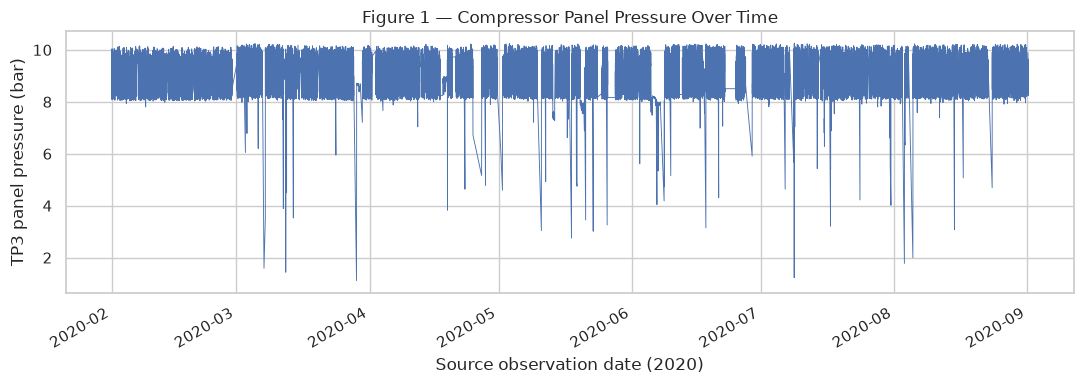

In [4]:
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(clean['timestamp'],clean['TP3'],linewidth=.65)
ax.set(title='Figure 1 — Compressor Panel Pressure Over Time',
       xlabel='Source observation date (2020)',ylabel='TP3 panel pressure (bar)')
fig.autofmt_xdate();plt.tight_layout();plt.show()


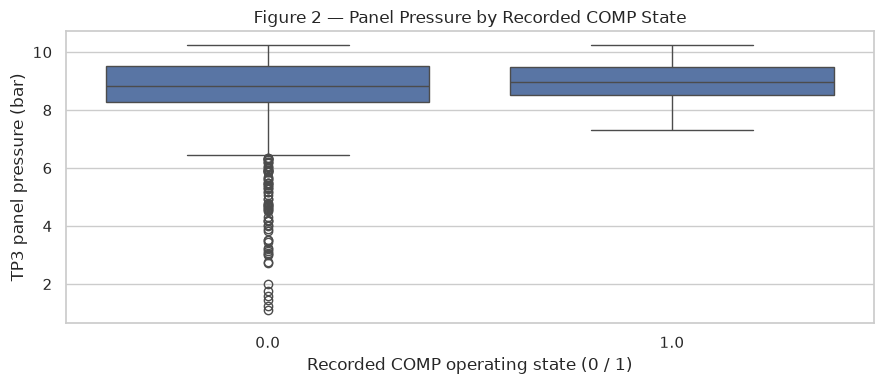

In [5]:
fig,ax=plt.subplots(figsize=(9,4))
sns.boxplot(data=clean,x='COMP',y='TP3',ax=ax)
ax.set(title='Figure 2 — Panel Pressure by Recorded COMP State',
       xlabel='Recorded COMP operating state (0 / 1)',ylabel='TP3 panel pressure (bar)')
plt.tight_layout();plt.show()


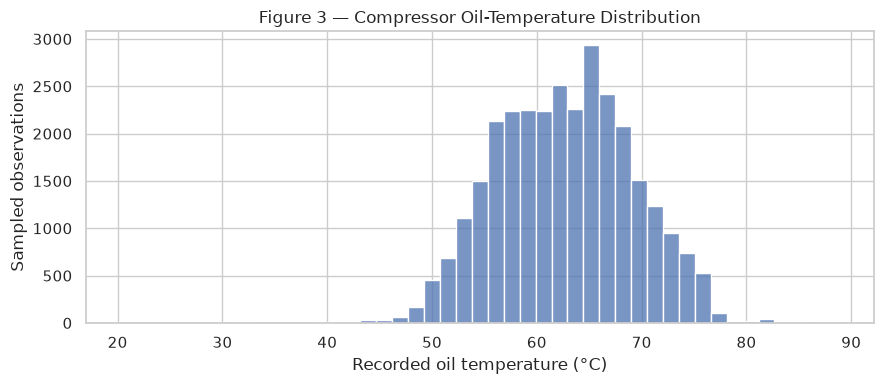

In [6]:
fig,ax=plt.subplots(figsize=(9,4))
sns.histplot(data=clean,x='Oil_temperature',bins=45,ax=ax)
ax.set(title='Figure 3 — Compressor Oil-Temperature Distribution',
       xlabel='Recorded oil temperature (°C)',ylabel='Sampled observations')
plt.tight_layout();plt.show()


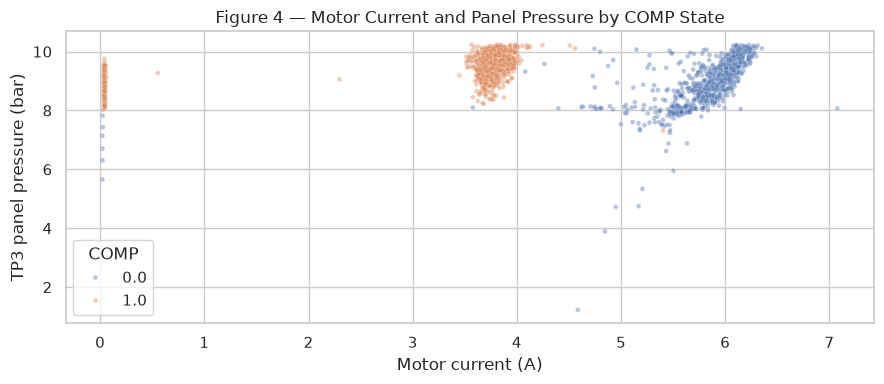

In [7]:
subset=clean.sample(n=min(len(clean),5000),random_state=42)
fig,ax=plt.subplots(figsize=(9,4))
sns.scatterplot(data=subset,x='Motor_current',y='TP3',hue='COMP',
                alpha=.4,s=12,ax=ax)
ax.set(title='Figure 4 — Motor Current and Panel Pressure by COMP State',
       xlabel='Motor current (A)',ylabel='TP3 panel pressure (bar)')
plt.tight_layout();plt.show()


## Comparison of the visual models
**Figure 1 (time-series line chart)** shows when pressure changes over the observed months; it is best for locating long-term time patterns but does not directly quantify differences by COMP operating state.
**Figure 2 (boxplot)** compares the center and spread of pressure readings for COMP=0 and COMP=1; of the initial four visualizations, it best supports our operating-state pressure research question, although its raw samples are temporally correlated.
**Figure 3 (histogram)** describes the range and most common oil-temperature readings but does not compare the pressure outcome between states.
**Figure 4 (scatterplot)** illustrates relationships between motor current and pressure stratified by COMP state, highlighting possible operating-context differences that a one-variable plot misses.
These views complement one another; the paired daily analysis and Figure 5 are used for the formal test because within-day pairing better accounts for changing day-to-day operating conditions than a raw boxplot alone.


## 5. Statistical hypothesis test — paired within-day pressure difference

**Null hypothesis (H₀):** For dates containing both COMP states, the population mean of the *within-date difference* in TP3 panel pressure (COMP=1 minus COMP=0) is zero.

**Alternative hypothesis (H₁):** The population mean of the within-date difference is not zero.

**Procedure:** Aggregate each operating state to one mean TP3 reading per calendar date. Include only dates with both COMP=0 and COMP=1; compute their paired daily differences. Conduct a two-sided paired-sample t-test and show the test statistic, p-value, 95% t confidence interval, sample size, effect size and conclusion at α = .05.

**Why aggregate?** Raw 1 Hz readings are autocorrelated; treating every row as an independent replication overstates statistical confidence. Paired daily means reduce pseudoreplication and control for differences between calendar days, although adjacent days and within-day observations may remain dependent. This analysis is exploratory, not a randomized causal experiment. There is no per-observation failure label.

In [8]:
clean['observation_day']=clean['timestamp'].dt.date
daily_state=(clean.groupby(['observation_day','COMP'])['TP3']
             .agg(['mean','size']).reset_index())
means=daily_state.pivot(index='observation_day',columns='COMP',values='mean')
counts=daily_state.pivot(index='observation_day',columns='COMP',values='size')
paired=means.dropna(subset=[0.0,1.0]).copy()
paired['difference_bar']=paired[1.0]-paired[0.0]
differences=paired['difference_bar'].to_numpy(dtype=float)
assert len(differences)>=3
result=stats.ttest_1samp(differences,popmean=0,alternative='two-sided')
n=len(differences)
estimate=float(differences.mean())
sd=float(differences.std(ddof=1))
se=sd/np.sqrt(n)
ci=stats.t.interval(confidence=.95,df=n-1,loc=estimate,scale=se)
effect_size=estimate/sd if sd else np.nan
print('Paired days with both states:',n,'out of',len(means),'observed days')
print('Observations COMP=0:',int((clean.COMP==0).sum()),'COMP=1:',int((clean.COMP==1).sum()))
print('Mean paired daily difference (COMP=1 minus COMP=0), bar:',round(estimate,6))
print('Paired t statistic:',round(float(result.statistic),6))
print('Degrees of freedom:',n-1)
print('Two-sided p-value:',float(result.pvalue))
print('95% CI for difference (bar):',tuple(round(float(x),6) for x in ci))
print('Cohen dz:',round(float(effect_size),4))
print('Decision at alpha=.05:', 'REJECT H0' if result.pvalue < .05 else 'DO NOT REJECT H0')
display(paired.head())


Paired days with both states: 205 out of 212 observed days
Observations COMP=0: 4940 COMP=1: 25399
Mean paired daily difference (COMP=1 minus COMP=0), bar: 0.015469
Paired t statistic: 0.45267
Degrees of freedom: 204
Two-sided p-value: 0.6512674972857992
95% CI for difference (bar): (-0.051908, 0.082846)
Cohen dz: 0.0316
Decision at alpha=.05: DO NOT REJECT H0


COMP,0.0,1.0,difference_bar
observation_day,,,
2020-02-01,9.221333,8.968168,-0.253165
2020-02-02,9.027333,9.017535,-0.009798
2020-02-03,9.053250,8.941795,-0.111455
2020-02-04,8.915333,8.937742,0.022409
2020-02-05,8.924308,8.949022,0.024715


## 6. Diagnostic checks and sensitivity analysis
Because the tested unit is the day (not an individual reading), inspect paired differences and check whether inference persists under a distribution-free sign-flip test. Neither check proves temporal independence.

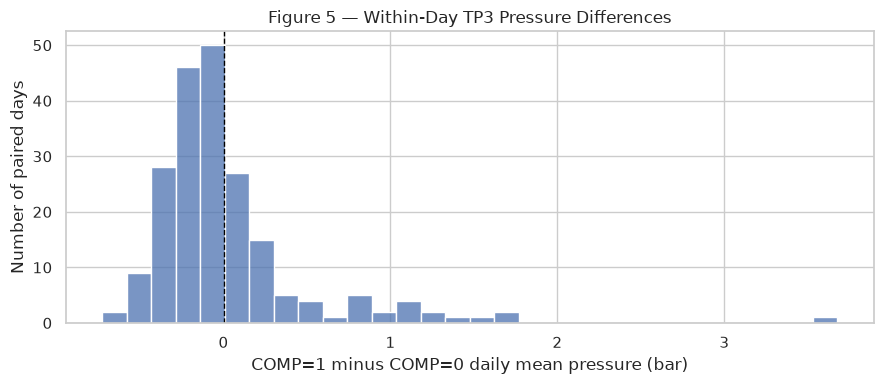

Sign-flip permutation p-value (20,000 fixed-seed draws): 0.660017
Caution: sign-flip validity assumes symmetric, approximately independent daily differences.


In [9]:
fig,ax=plt.subplots(figsize=(9,4))
sns.histplot(differences,bins=30,ax=ax)
ax.axvline(0,color='black',linestyle='--',linewidth=1)
ax.set(title='Figure 5 — Within-Day TP3 Pressure Differences',
       xlabel='COMP=1 minus COMP=0 daily mean pressure (bar)',
       ylabel='Number of paired days')
plt.tight_layout();plt.show()
rng=np.random.default_rng(2026)
n_draws=20000
observed=np.abs(estimate)
permuted=np.empty(n_draws)
for i in range(n_draws):
    signs=rng.choice([-1,1],size=n)
    permuted[i]=np.abs(np.mean(differences*signs))
permutation_p=(np.sum(permuted>=observed)+1)/(n_draws+1)
print('Sign-flip permutation p-value (20,000 fixed-seed draws):',round(permutation_p,6))
print('Caution: sign-flip validity assumes symmetric, approximately independent daily differences.')


## 7. Summary
This analysis explored real MetroPT-3 compressor pressure, oil temperature, motor current, and the recorded COMP operating state using descriptive statistics and five visualizations.
Figure 2 was the most directly relevant initial visualization for comparing pressure across states, while the time-series, histogram, and scatterplot supplied additional context.
Across 205 days with both states observed, the paired mean pressure difference was approximately 0.0155 bar, and the two-sided test did not reject the null hypothesis (p = 0.6513).
It was noteworthy that many raw measurements did not translate into evidence of a meaningful average within-day state difference.
The main challenges were serial dependence, unequal state frequencies, and the potential loss of short-duration events through systematic subsampling.
These findings describe a single research compressor and should not be interpreted as verified failures or predictions for operational QIAIP assets.
